# 05 — De la prédiction à la décision : coûts, seuil, ROI et risques

On utilise **les prédictions du test** (notebook 04) ; aucun modèle n'est ré-entraîné.

### Rappel du cadrage
| Élément | Réponse |
|---|---|
| Utilisateur | Centre d'alerte tsunami couvrant l'Alaska (ex. National Tsunami Warning Center, NOAA) |
| Décision | Déclencher ou non l'**alerte tsunami majeure** (évacuation côtière large) |
| Moment | **5 minutes** (300 s) après le début d'un séisme de Mw ≥ 7 détecté dans la zone |
| Situation actuelle | Les estimations rapides (ondes P) **saturent** vers Mw 7–8 ; l'estimation fiable (phase W) prend **≈ 20 min** (mémoire Q. Bletery, §I.4.2) |
| Critère de succès | Identifier à 5 min au moins **75 %** des séismes majeurs (Mw ≥ 8,5), pour un coût total attendu **inférieur** à la situation actuelle |
| Contraintes | Seuls les signaux arrivés avant l'onde P ; décision en quelques minutes ; modèle explicable ; décision finale humaine |

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src import config as C, decision as Dc, pegs_io as io, generate as G
from src.predict import predict_magnitude

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
MODEL_DIR = C.PROJECT_ROOT / "models"

test = pd.read_csv(C.PROCESSED_DIR / "test.csv")
xgb = joblib.load(MODEL_DIR / "xgboost.joblib")
pred = xgb["model"].predict(test[xgb["features"]])
mw = test.mw.values
H = dict(Dc.HYP)

## 1. Les hypothèses (toutes explicites, modifiables dans `src/decision.py`)

| Hypothèse | Valeur centrale | Source / justification |
|---|---|---|
| Séismes de Mw ≥ 7 en Alaska | ≈ 1,08 / an | Alaska Earthquake Center : « un séisme de magnitude 7 à 8 par an », « un séisme ≥ 8 tous les 13 ans » (moyennes depuis 1900) |
| Loi de fréquence | Gutenberg-Richter, b ≈ 1,15 | déduite des deux taux ci-dessus ; b ≈ 1 en général (mémoire, éq. I-5) |
| Séisme « majeur » | Mw ≥ 8,5 | tsunami inexistant sous Mw 8, très destructeur au-delà de 9 (mémoire, §I.4.2) |
| Coût d'une évacuation tsunami | 30 M$ | ≈ 30 M$ par fausse alerte à Hawaï (D. Walker, *Honolulu Star-Bulletin*, 1999) ; NOAA/ITIC : 40 M$ en 1986 (75 M$ en dollars de 2013) |
| Coût d'une alerte majeure **en retard** | 10 victimes évitables × 14,2 M$ | **hypothèse non sourcée** (testée de 1 à 100) × valeur statistique d'une vie de l'US DOT (14,2 M$, dollars 2025) |
| Coût du projet, an 1 | 60 + 60 + 30 = **150 k$** | **hypothèses** : développement (2 data scientists × 3 mois), intégration temps réel + validation sismologue, exploitation annuelle |

**Matrice de coûts par séisme** (dans la situation « alerte majeure à 5 min ou non ») :

| | Alerte majeure déclenchée | Pas d'alerte majeure à 5 min |
|---|---|---|
| **Séisme majeur** (Mw ≥ 8,5) | Vrai positif : évacuation justifiée = **30 M$** | Faux négatif : évacuation **en retard** (phase W) = 30 + 10 × 14,2 = **172 M$** |
| **Séisme non majeur** | Faux positif : évacuation inutile = **30 M$** | Vrai négatif : **0** |

In [2]:
c = Dc.unit_costs(H)
print(f"b-value déduite : {Dc.gr_b_value(H):.2f}")
print("Coûts unitaires (M$) :", {k: round(v, 1) for k, v in c.items()})
print(f"Rapport coût FN / coût FP : {c['FN'] / c['FP']:.1f}")

b-value déduite : 1.15
Coûts unitaires (M$) : {'VP': 30.0, 'FP': 30.0, 'FN': 172.0, 'VN': 0.0}
Rapport coût FN / coût FP : 5.7


## 2. Traduire la MAE en langage métier

La magnitude est **logarithmique** : 1 unité de Mw = un facteur 10^1,5 ≈ 32 sur le moment sismique (l'« énergie »
libérée par la faille).

In [3]:
def facteur(dmw):
    return 10 ** (1.5 * dmw)
maj = mw >= H["seuil_majeur"]
mae_all = np.abs(pred - mw).mean(); mae_maj = np.abs(pred[maj] - mw[maj]).mean()
print(f"MAE test (tous séismes)       : {mae_all:.2f} -> erreur typique d'un facteur {facteur(mae_all):.1f} sur le moment sismique")
print(f"MAE test (séismes Mw ≥ 8,5)   : {mae_maj:.2f} -> facteur {facteur(mae_maj):.1f}")
print(f"Séismes majeurs estimés à ± 0,4 : {100 * (np.abs(pred[maj] - mw[maj]) < 0.4).mean():.0f} %")
print(f"Pour comparaison, Tohoku 2011 : estimation rapide JMA ≈ 8,1 pour Mw 9,0 (Licciardi et al. 2022) "
      f"-> facteur {facteur(0.9):.0f}")

MAE test (tous séismes)       : 0.29 -> erreur typique d'un facteur 2.8 sur le moment sismique
MAE test (séismes Mw ≥ 8,5)   : 0.33 -> facteur 3.1
Séismes majeurs estimés à ± 0,4 : 71 %
Pour comparaison, Tohoku 2011 : estimation rapide JMA ≈ 8,1 pour Mw 9,0 (Licciardi et al. 2022) -> facteur 22


**Lecture** : une MAE de 0,29 signifie une erreur typique d'un facteur **≈ 3 sur le moment sismique** (l'énergie
libérée), aussi bien sur l'ensemble que sur les séismes majeurs. 71 % des séismes majeurs sont estimés à ± 0,4 près
(critère de succès utilisé par PEGSNet). À titre de comparaison, l'estimation rapide du séisme de Tohoku en 2011
(≈ 8,1 pour un Mw 9,0) se trompait d'un facteur **≈ 22**. Attention cependant : 17 % des Mw ≥ 9 restent sous-estimés
de plus de 0,5 (notebook 04).

## 3. Remettre les fréquences à l'échelle de la réalité

Notre base de test a des magnitudes **uniformes** (autant de Mw 9 que de Mw 7). En réalité, il y a environ 14 fois
plus de Mw 7 que de Mw 8 (b ≈ 1,15). On **repondère** chaque séisme de test pour retrouver les fréquences réelles
(`Dc.annual_weights`) : sans cela, la précision et les coûts seraient très optimistes.

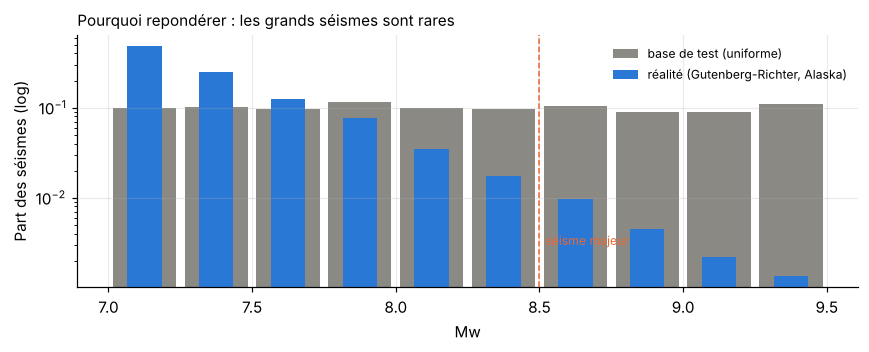

Séismes Mw ≥ 7 attendus par an : 1.08 | séismes majeurs (≥ 8,5) par an : 0.0191 -> un tous les 52 ans environ


In [4]:
w = Dc.annual_weights(mw, H)
bins = np.arange(7, 9.51, 0.25)
fig, ax = plt.subplots(figsize=(8, 3.3))
cnt, _ = np.histogram(mw, bins); rate, _ = np.histogram(mw, bins, weights=w)
ax.bar(bins[:-1] + 0.125, cnt / cnt.sum(), width=0.22, color=C.C_MUTED, label="base de test (uniforme)")
ax.bar(bins[:-1] + 0.125, rate / rate.sum(), width=0.12, color=C.C_SIGNAL, label="réalité (Gutenberg-Richter, Alaska)")
ax.axvline(H["seuil_majeur"], color=C.C_NOISY, ls="--", lw=1); ax.text(8.52, 3e-3, "séisme majeur", fontsize=8, color=C.C_NOISY)
ax.set_yscale("log"); ax.set_xlabel("Mw"); ax.set_ylabel("Part des séismes (log)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Pourquoi repondérer : les grands séismes sont rares", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "05_reponderation.png"); plt.show()
print(f"Séismes Mw ≥ 7 attendus par an : {w.sum():.2f} | séismes majeurs (≥ 8,5) par an : {w[maj].sum():.4f} "
      f"-> un tous les {1 / w[maj].sum():.0f} ans environ")

## 4. Analyse du seuil d'alerte

On compare plusieurs seuils « alerte majeure si Mw prédite ≥ s ». Les nombres d'événements sont exprimés
**pour 100 ans** (plus parlant que des fractions par an).

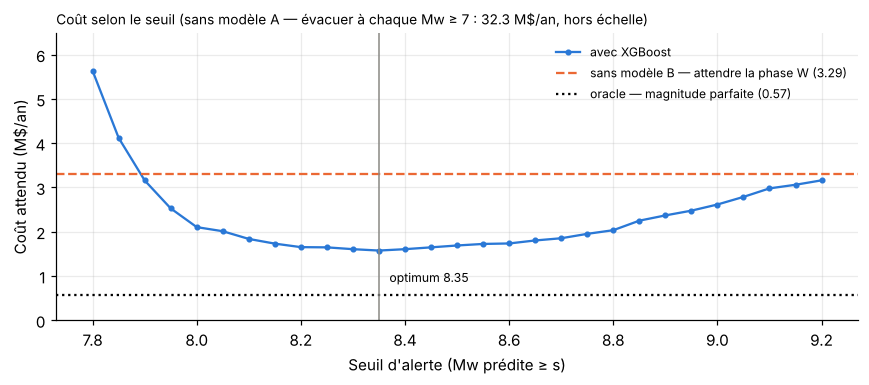

Seuil optimal (scénario central) : 8.35 — coût 1.57 M$/an


,rappel (%),précision réaliste (%),précision base uniforme (%),majeurs détectés /100 ans,majeurs manqués /100 ans,fausses évacuations /100 ans,coût attendu (M$/an)
seuil,,,,,,,
8.0,88.48,29.48,74.28,1.69,0.22,4.05,2.10
8.2,82.11,44.40,81.64,1.57,0.34,1.97,1.65
8.3,78.06,50.80,84.55,1.49,0.42,1.45,1.60
8.5,67.24,63.33,89.13,1.29,0.63,0.75,1.69


In [5]:
rows = []
for s in [8.0, 8.2, 8.3, 8.5]:
    cm = Dc.confusion(mw, pred, s, H, w)
    rows.append({"seuil": s,
                 "rappel (%)": 100 * cm["VP"] / (cm["VP"] + cm["FN"]),
                 "précision réaliste (%)": 100 * cm["VP"] / (cm["VP"] + cm["FP"]),
                 "précision base uniforme (%)": 100 * Dc.confusion(mw, pred, s, H)["VP"] / (Dc.confusion(mw, pred, s, H)["VP"] + Dc.confusion(mw, pred, s, H)["FP"]),
                 "majeurs détectés /100 ans": 100 * cm["VP"], "majeurs manqués /100 ans": 100 * cm["FN"],
                 "fausses évacuations /100 ans": 100 * cm["FP"], "coût attendu (M$/an)": Dc.annual_cost(cm, H)})
seuils = pd.DataFrame(rows).set_index("seuil")

grid = np.round(np.arange(7.8, 9.21, 0.05), 2)
costs = np.array([Dc.annual_cost(Dc.confusion(mw, pred, s, H, w), H) for s in grid])
s_opt = grid[np.argmin(costs)]
pol = Dc.policies(mw, pred, H)
cA, cB, cO = pol.iloc[0, -1], pol.iloc[1, -1], pol.iloc[2, -1]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid, costs, "o-", ms=3, color=C.C_SIGNAL, label="avec XGBoost")
ax.axhline(cB, color=C.C_NOISY, ls="--", label=f"sans modèle B — attendre la phase W ({cB:.2f})")
ax.axhline(cO, color="k", ls=":", label=f"oracle — magnitude parfaite ({cO:.2f})")
ax.axvline(s_opt, color=C.C_MUTED, lw=1)
ax.text(s_opt + 0.02, costs.min() * 0.55, f"optimum {s_opt:.2f}", fontsize=8)
ax.set_xlabel("Seuil d'alerte (Mw prédite ≥ s)"); ax.set_ylabel("Coût attendu (M$/an)")
ax.set_title(f"Coût selon le seuil (sans modèle A — évacuer à chaque Mw ≥ 7 : {cA:.1f} M$/an, hors échelle)", loc="left", fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="upper right"); ax.set_ylim(0, max(costs.max(), cB) * 1.15)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "05_cout_vs_seuil.png"); plt.show()
print(f"Seuil optimal (scénario central) : {s_opt:.2f} — coût {costs.min():.2f} M$/an")
seuils.to_csv(C.PROJECT_ROOT / "reports" / "05_analyse_seuil.csv")
seuils.round(2)

**Lecture et choix du seuil** : 
- La **repondération change tout** pour la précision : au seuil 8,3, elle passe de 85 % (base uniforme) à **51 %**
  (fréquences réelles), soit environ **une fausse évacuation par alerte justifiée**. Le rappel varie peu (78 %).
- **En 100 ans** au seuil 8,3 : ~1,5 séisme majeur identifié à temps, ~0,4 manqué, ~1,5 évacuation inutile.
- Le coût attendu est **minimal vers 8,35** (1,57 M$/an) et reste **plat entre 8,2 et 8,6** : le choix est robuste.
  En dessous de ~7,9, le modèle devient **pire que l'attente de la phase W** : on retombe dans le plancher de bruit
  (prédictions ≈ 7,6–8,0 même sans séisme visible) et les fausses alertes explosent.
- **Seuil retenu : 8,3.** Il est quasi optimal (1,60 M$/an) et respecte le critère de succès (rappel ≥ 75 %).
  Le seuil 8,5, plus intuitif, tomberait à 67 % de rappel.

## 5. ROI

Gain annuel = coût sans modèle − coût avec modèle ; ROI = (gain − coût du projet) / coût du projet ;
délai de retour = coût du projet / (gain annuel / 12).

On prend comme référence principale la situation la **plus défavorable au projet** : *B — attendre la phase W*
(elle coûte bien moins cher que d'évacuer à chaque séisme).

In [6]:
SEUIL = 8.3
pol = Dc.policies(mw, pred, H, seuils=(SEUIL,))
display(pol.round(4))
gain_B = pol.iloc[1, -1] - pol.iloc[3, -1]
gain_A = pol.iloc[0, -1] - pol.iloc[3, -1]
roi_B, roi_A = Dc.roi(gain_B, H), Dc.roi(gain_A, H)
pd.DataFrame({"vs B (attendre la phase W)": roi_B, "vs A (évacuer à chaque Mw ≥ 7)": roi_A}).round(2)

,VP,FP,FN,VN,coût annuel attendu (M$/an)
politique,,,,,
Sans modèle A — évacuer pour tout Mw ≥ 7 (prudente),0.0191,1.0563,0.0000,0.0000,32.2636
Sans modèle B — attendre la phase W (~20 min),0.0000,0.0000,0.0191,1.0563,3.2925
Oracle (magnitude parfaite à 5 min),0.0191,0.0000,0.0000,1.0563,0.5743
XGBoost — alerte si Mw prédite ≥ 8.3,0.0149,0.0145,0.0042,1.0418,1.6049


,vs B (attendre la phase W),vs A (évacuer à chaque Mw ≥ 7)
coût projet an 1 (M$),0.15,0.15
gain annuel attendu (M$),1.69,30.66
ROI an 1 (%),1025.10,20339.18
délai de retour (mois),1.07,0.06


**Lecture** : 
- Par rapport à **B (attendre la phase W)**, le coût attendu passe de **3,29 à 1,60 M$/an** : gain ≈ **1,7 M$/an** pour un
  projet à 0,15 M$, soit un **ROI an 1 ≈ 1 000 %** et un retour en ~1 mois. Par rapport à **A (évacuer à chaque séisme)**,
  le gain serait de 30,7 M$/an, mais A est une référence peu réaliste.
- ⚠️ **Il s'agit d'une espérance.** Un séisme majeur survient en moyenne une fois tous les ~52 ans. La plupart des
  années, il ne se passe rien, et le modèle ne déclenche qu'environ 0,015 fausse évacuation par an. La valeur du projet
  ressemble à une **assurance** : elle est concentrée sur un événement rare mais catastrophique. Un ROI de 1 000 % ne
  veut **pas** dire « 1,7 M$ économisés chaque année ».

## 6. Analyse de sensibilité : de quoi dépend le résultat ?

On fait varier **une hypothèse à la fois** autour du scénario central (référence B, seuil 8,3), puis on combine
dans trois scénarios. Le scénario « modèle dégradé » décale toutes les prédictions de −0,3 pour simuler l'écart
synthétique → réel (sous-estimation supplémentaire).

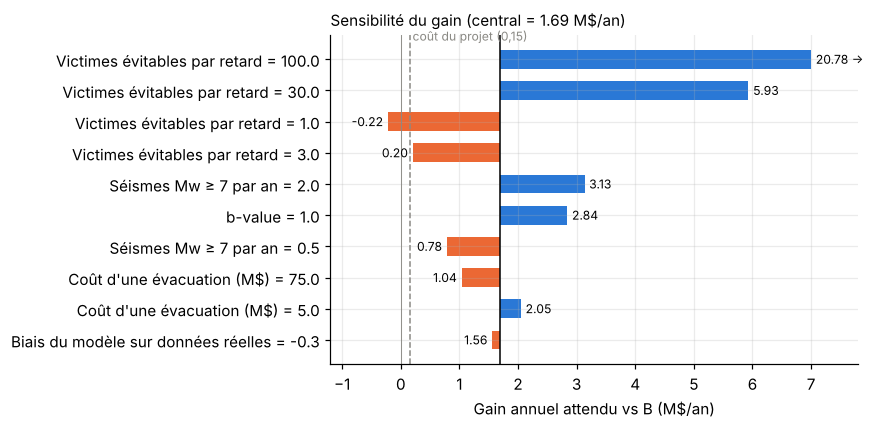

Le projet est rentable (an 1) dès 3.0 victime(s) évitée(s) par séisme majeur identifié à temps.


,hypothèse,valeur testée,gain vs B (M$/an),écart au central
0,Victimes évitables par retard,1.0,-0.222,-1.910
1,Victimes évitables par retard,3.0,0.202,-1.485
2,Victimes évitables par retard,30.0,5.931,4.244
3,Victimes évitables par retard,100.0,20.784,19.096
4,Coût d'une évacuation (M$),5.0,2.049,0.362
5,Coût d'une évacuation (M$),75.0,1.036,-0.651
6,Séismes Mw ≥ 7 par an,0.5,0.784,-0.904
7,Séismes Mw ≥ 7 par an,2.0,3.134,1.447
8,b-value,1.0,2.841,1.153
9,Biais du modèle sur données réelles,-0.3,1.558,-0.129


In [7]:
def gain_vs_B(h, p=pred, s=SEUIL):
    pol = Dc.policies(mw, p, h, seuils=(s,))
    return pol.iloc[1, -1] - pol.iloc[3, -1]

def with_rate(h, n7, b=None):
    h = dict(h); b = Dc.gr_b_value(h) if b is None else b
    h["N_ge7_par_an"] = n7; h["N_ge8_par_an"] = n7 / 10 ** b
    return h

tests = []
for v in [1, 3, 30, 100]:
    tests.append(("Victimes évitables par retard", v, gain_vs_B({**H, "victimes_evitables_par_retard": v})))
for v in [5, 75]:
    tests.append(("Coût d'une évacuation (M$)", v, gain_vs_B({**H, "cout_evacuation_M$": v})))
for v in [0.5, 2.0]:
    tests.append(("Séismes Mw ≥ 7 par an", v, gain_vs_B(with_rate(H, v))))
tests.append(("b-value", 1.0, gain_vs_B(with_rate(H, H["N_ge7_par_an"], b=1.0))))
for d in [-0.3]:
    tests.append(("Biais du modèle sur données réelles", d, gain_vs_B(H, p=pred + d)))
sens = pd.DataFrame(tests, columns=["hypothèse", "valeur testée", "gain vs B (M$/an)"])
g0 = gain_vs_B(H)
sens["écart au central"] = sens["gain vs B (M$/an)"] - g0

fig, ax = plt.subplots(figsize=(8, 4))
lab = [f"{h} = {v}" for h, v in zip(sens["hypothèse"], sens["valeur testée"])]
order = np.argsort(np.abs(sens["écart au central"].values))
cols = [C.C_SIGNAL if x > 0 else C.C_NOISY for x in sens["écart au central"].values[order]]
XMAX = 7
vals = sens["gain vs B (M$/an)"].values[order]
ax.barh(np.array(lab)[order], np.minimum(vals, XMAX) - g0, left=g0, color=cols, height=0.6)
for yi, v in enumerate(vals):
    ax.text(min(v, XMAX) + (0.08 if v >= g0 else -0.08), yi, f"{v:.2f}" + (" →" if v > XMAX else ""),
            va="center", ha="left" if v >= g0 else "right", fontsize=8)
ax.axvline(g0, color="k", lw=1); ax.axvline(Dc.project_cost_year1(H), color=C.C_MUTED, ls="--", lw=1)
ax.axvline(0, color=C.C_MUTED, lw=0.6)
ax.text(Dc.project_cost_year1(H) + 0.05, len(vals) - 0.4, "coût du projet (0,15)", fontsize=8, color=C.C_MUTED)
ax.set_xlim(-1.2, XMAX + 0.8); ax.set_xlabel("Gain annuel attendu vs B (M$/an)")
ax.set_title(f"Sensibilité du gain (central = {g0:.2f} M$/an)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "05_sensibilite.png"); plt.show()

# Seuil de rentabilité sur l'hypothèse la plus critique
vs = np.round(np.arange(0.5, 10.01, 0.25), 2)
be = next(v for v in vs if gain_vs_B({**H, "victimes_evitables_par_retard": v}) > Dc.project_cost_year1(H))
print(f"Le projet est rentable (an 1) dès {be} victime(s) évitée(s) par séisme majeur identifié à temps.")
sens.round(3)

In [8]:
scen = {
    "Pessimiste": {**with_rate(H, 0.5), "victimes_evitables_par_retard": 1, "cout_evacuation_M$": 75.0},
    "Central": dict(H),
    "Optimiste": {**with_rate(H, H["N_ge7_par_an"], b=1.0), "victimes_evitables_par_retard": 30, "cout_evacuation_M$": 5.0},
}
shift = {"Pessimiste": -0.3, "Central": 0.0, "Optimiste": 0.0}
rows = []
for name, h in scen.items():
    g = gain_vs_B(h, p=pred + shift[name]); r = Dc.roi(g, h)
    rows.append({"scénario": name, "victimes évitables": h["victimes_evitables_par_retard"],
                 "coût évacuation (M$)": h["cout_evacuation_M$"], "Mw ≥ 7 / an": round(h["N_ge7_par_an"], 2),
                 "b": round(Dc.gr_b_value(h), 2), "biais modèle": shift[name],
                 "gain vs B (M$/an)": g, "ROI an 1 (%)": r["ROI an 1 (%)"], "retour (mois)": r["délai de retour (mois)"]})
scen_df = pd.DataFrame(rows).set_index("scénario")
scen_df.to_csv(C.PROJECT_ROOT / "reports" / "05_scenarios_roi.csv")
scen_df.round(2)

,victimes évitables,coût évacuation (M$),Mw ≥ 7 / an,b,biais modèle,gain vs B (M$/an),ROI an 1 (%),retour (mois)
scénario,,,,,,,,
Pessimiste,1,75.0,0.50,1.15,-0.3,-0.10,-164.17,inf
Central,10,30.0,1.08,1.15,0.0,1.69,1025.10,1.07
Optimiste,30,5.0,1.08,1.00,0.0,10.16,6674.93,0.18


**Lecture** : 
- **L'hypothèse la plus critique est le nombre de victimes évitées** quand l'alerte majeure part à 5 min plutôt qu'à
  ~20 min. Le projet n'est rentable qu'à partir de **3 victimes évitées par séisme majeur**. Avec 1 seule, le gain devient
  **négatif** : les fausses évacuations déclenchées par le modèle coûtent plus que le temps gagné.
- Viennent ensuite la **fréquence des séismes** (0,5 à 2 par an) et la **b-value**. Le coût d'une évacuation compte peu,
  car il pèse à la fois sur la situation actuelle et sur le modèle.
- Un **biais supplémentaire de −0,3** sur données réelles (écart synthétique → réel) ne réduit le gain que de 8 %,
  parce que le seuil 8,3 laisse une marge.
- **Scénario pessimiste** (1 victime évitable, évacuation à 75 M$, 0,5 séisme par an, modèle biaisé) : **ROI négatif
  (−164 %)**, et le projet ne se justifie pas. Scénario central : ROI ≈ 1 000 % ; scénario optimiste : ≈ 6 700 %.
- **À valider en priorité avec le centre d'alerte** : combien de vies une alerte 15 minutes plus tôt sauverait-elle sur
  les côtes proches de la source (temps d'arrivée du tsunami, population exposée) ?

## 7. Stress tests de robustesse (préparation du registre des risques)

On régénère 300 séismes de test et on dégrade volontairement les conditions, comme cela pourrait arriver en temps réel :
- **arrivée de l'onde P mal pointée** : erreur aléatoire de ± 5 s (écart-type), ou pointé systématiquement 10 s trop tôt ;
- **bruit plus fort** que dans la base (×1,5 et ×2 ; les séismes réels de Kodiak et Chignik étaient 1,5 à 2 fois plus bruités) ;
- **stations en panne** : 20 % et 40 % de stations retirées au hasard.

In [9]:
kernels = io.load_kernels(C.KERNEL_FILE); noise = io.load_noise(C.NOISE_FILE)
rng = np.random.default_rng(C.RANDOM_STATE)
t_rel = np.arange(601) - C.GRAPH_ORIGIN_IDX
rows = []
for i, ev in enumerate(G.iter_events(C.N_TEST, C.NOISE_TEST, kernels, noise, seed=C.SEED_TEST, mw_range=C.MW_RANGE)):
    if i == 300:
        break
    d, tp, fl = ev["data"].astype(float), ev["tp"], ev["flag"]
    nz = noise["noise"][ev["noise_window"], :, ev["noise_start"]:ev["noise_start"] + 601].astype(float)
    nz = np.where(t_rel[None, :] > tp[:, None], 0.0, nz); nz[~fl] = 0.0
    r = {"mw": ev["mw"], "référence": predict_magnitude(d, tp, fl),
         "P ± 5 s": predict_magnitude(d, tp + rng.normal(0, 5, len(tp)), fl),
         "P 10 s trop tôt": predict_magnitude(d, tp - 10, fl),
         "bruit × 1,5": predict_magnitude(d + 0.5 * nz, tp, fl),
         "bruit × 2": predict_magnitude(d + 1.0 * nz, tp, fl)}
    for frac in (0.2, 0.4):
        off = rng.random(len(fl)) < frac
        f2, d2 = fl.copy(), d.copy(); f2[off] = False; d2[off] = 0.0
        r[f"{int(frac * 100)} % stations en panne"] = predict_magnitude(d2, tp, f2)
    rows.append(r)
st = pd.DataFrame(rows)
cls = pd.cut(st.mw, [7, 8, 9.5], labels=["Mw < 8", "Mw ≥ 8"])
conds = [c for c in st.columns if c != "mw"]
stress = pd.concat({
    "MAE Mw ≥ 8": pd.Series({c: (st[c] - st.mw)[cls == "Mw ≥ 8"].abs().mean() for c in conds}),
    "biais Mw ≥ 8": pd.Series({c: (st[c] - st.mw)[cls == "Mw ≥ 8"].mean() for c in conds}),
    "décalage moyen vs référence, Mw < 8": pd.Series({c: (st[c] - st["référence"])[cls == "Mw < 8"].mean() for c in conds}),
}, axis=1)
stress.to_csv(C.PROJECT_ROOT / "reports" / "05_stress_tests.csv")
stress.round(3)

,MAE Mw ≥ 8,biais Mw ≥ 8,"décalage moyen vs référence, Mw < 8"
référence,0.357,-0.232,0.000
P ± 5 s,0.413,-0.319,-0.089
P 10 s trop tôt,0.464,-0.389,-0.032
"bruit × 1,5",0.415,-0.344,0.088
bruit × 2,0.502,-0.463,0.074
20 % stations en panne,0.321,-0.147,0.241
40 % stations en panne,0.284,-0.028,0.565


**Lecture** : 
- **Pointé de l'onde P** : une erreur de ± 5 s fait passer la MAE (Mw ≥ 8) de 0,36 à **0,41**, et un pointé 10 s trop
  tôt à **0,46**. C'est logique : les caractéristiques les plus importantes sont justement les valeurs juste avant l'onde P
  (notebook 04). Or nos temps d'arrivée P sont théoriques et exacts : c'est un **risque réel**.
- **Bruit plus fort** : ×1,5 donne une MAE de **0,42**, ×2 une MAE de **0,50**, avec une sous-estimation qui s'aggrave
  (biais −0,46). Les séismes réels de Kodiak et Chignik étaient justement 1,5 à 2 fois plus bruités.
- **Stations en panne** : la MAE des grands séismes semble **s'améliorer** (0,32 puis 0,28), mais c'est un **artefact**.
  Les prédictions sont décalées **vers le haut** (+0,24 et +0,57 pour les Mw < 8), ce qui compense par hasard la
  sous-estimation des grands séismes et multiplierait les **fausses alertes**. Le modèle n'est **pas robuste** à un réseau
  incomplet (il a été entraîné avec ~5 % de stations manquantes). Cela concerne Chignik 2021 (169 stations sur 273).

## 8. Registre des risques

| # | Risque | Catégorie | Probabilité | Impact | Constat dans ce projet | Mesure de réduction |
|---|---|---|---|---|---|---|
| 1 | Écart entre données synthétiques et réelles | Technique | Élevée | Élevé | Entraînement 100 % synthétique (hors bruit) ; 1 séisme réel détecté sur 4 | Phase d'observation (« shadow mode » : le modèle tourne sans décider) sur plusieurs années ; bilan après chaque séisme réel ; plus de positions de source (fichiers QSSP fournis) |
| 2 | Bruit réel plus fort que dans la base | Technique | Moyenne | Élevé | Bruit ×2 : MAE (Mw ≥ 8) de 0,36 à 0,50 ; Kodiak et Chignik 1,5 à 2 fois plus bruités | Base de bruit couvrant plusieurs saisons et années ; signaler la prédiction si le bruit pré-séisme dépasse celui de la base |
| 3 | Stations manquantes ou réseau modifié | Technique | Élevée | Élevé | 40 % de stations en panne : +0,57 sur les petits séismes (fausses alertes) | Entraîner en retirant des stations au hasard ; un modèle par configuration de réseau ; nombre minimal de stations actives |
| 4 | Arrivée de l'onde P mal pointée | Technique | Moyenne | Moyen | ± 5 s : MAE de 0,36 à 0,41 | Entraîner avec des temps d'arrivée P bruités ; couper le signal quelques secondes avant l'onde P |
| 5 | Sous-estimation des Mw ≥ 9 | Technique | Élevée | Élevé | 41 % sous-estimés de plus de 0,3 ; effet de bord à 9,5 | Entraîner jusqu'à Mw 10 ; règle de prudence au-dessus de ~8,8 ; ré-estimer toutes les 30 s |
| 6 | Prédiction sous le plancher de bruit lue comme une vraie valeur | Métier | Élevée | Moyen | Bruit pur : Mw 7,57 prédit | `predict_magnitude` signale « sous le seuil de détection » (< 7,96) ; affichage obligatoire de ce statut |
| 7 | Excès de confiance des opérateurs | Métier | Moyenne | Élevé | Erreur typique d'un facteur 3 sur le moment | Indicateur parmi d'autres, jamais seul décideur ; incertitude (± 0,4) affichée ; formation |
| 8 | Hypothèses de coût non validées | Métier | Élevée | Élevé | ROI négatif si moins de 3 victimes évitées par séisme majeur | Atelier avec le centre d'alerte et l'État d'Alaska ; recalcul du seuil avec les vrais coûts |
| 9 | Fatigue d'alerte | Métier | Faible | Moyen | ~1,5 évacuation inutile par siècle au seuil 8,3 | Revue après chaque alerte ; seuil revu si les coûts changent |
| 10 | Responsabilité en cas d'alerte manquée | Éthique / réglementaire | Faible | Élevé | ~0,4 séisme majeur manqué par siècle | Décision finale au centre d'alerte officiel ; journalisation des entrées, prédictions et versions du modèle |
| 11 | Protection inégale selon les zones côtières | Éthique | Moyenne | Élevé | Source à 64° N : MAE 0,59 contre 0,20–0,38 ailleurs | Publier la performance par zone ; densifier le réseau où l'erreur est forte ; ne pas utiliser le modèle hors de la zone couverte |
| 12 | Licences et données | Réglementaire | Faible | Faible | Dépôt PEGSGraph sous GPL-3.0 ; données sismiques publiques ; aucune donnée personnelle (RGPD non concerné) | Citer les sources ; vérifier la compatibilité de licence avant toute redistribution |
| 13 | Coût énergétique | Environnemental | Faible | Faible | Entraînement complet ≈ 20 min sur 2 cœurs CPU ; prédiction < 1 s ; pas de GPU | Ré-entraînement annuel seulement |

## 9. Recommandation (executive summary)

> **Nous proposons d'ajouter au centre d'alerte tsunami d'Alaska un indicateur fondé sur les PEGS, qui estime dès
> 5 minutes si un séisme est majeur (Mw ≥ 8,5), là où les estimations rapides actuelles saturent.** Sur 1 200 séismes
> synthétiques jamais vus, il identifie 78 % des séismes majeurs (fréquences réelles) avec une erreur typique de 0,3
> en magnitude. Sous nos hypothèses centrales, il réduit le coût attendu de 3,3 à 1,6 M$/an pour un projet de 150 k$.
> Ce résultat devient toutefois **négatif** si une alerte précoce sauve moins de 3 vies par séisme majeur, et un seul
> séisme réel sur 4 a été détecté. **Nous recommandons donc un déploiement en mode observation** (sans pouvoir de
> décision), couplé à l'enrichissement de la base (positions de source, bruit, stations manquantes) et à la validation
> des coûts avec le centre d'alerte, **avant tout usage opérationnel**.